# Exploratory Data Analysis (EDA) on Retail Sales Dataset
### Objective:
Perform an end-to-end exploratory analysis on retail transactional data to uncover customer behavior, seasonal sales trends, category performance, and generate data-driven business recommendations.


## 1. Environment Setup & Data Ingestion
Loading primary analytical libraries (Pandas, NumPy, Matplotlib, Seaborn) and importing the raw dataset. Inspecting structure, data types, and checking for missing values.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Load dataset
df = pd.read_csv('retail_sales_dataset.csv')

# Standardize column headers to lowercase snake_case
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("--- Column Information & Data Types ---")
print(df.info())
print("\n--- Missing Value Counts ---")
print(df.isnull().sum())

# Display first 5 records
df.head()

Dataset Shape: 1000 rows, 9 columns

--- Column Information & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   transaction_id    1000 non-null   int64
 1   date              1000 non-null   str  
 2   customer_id       1000 non-null   str  
 3   gender            1000 non-null   str  
 4   age               1000 non-null   int64
 5   product_category  1000 non-null   str  
 6   quantity          1000 non-null   int64
 7   price_per_unit    1000 non-null   int64
 8   total_amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB
None

--- Missing Value Counts ---
transaction_id      0
date                0
customer_id         0
gender              0
age                 0
product_category    0
quantity            0
price_per_unit      0
total_amount        0
dtype: int64


,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 2. Descriptive Statistics & Data Preprocessing
Converting date records into standard datetime format and calculating summary metrics (mean, median, mode, standard deviation, and quartiles) for all numerical features.

In [9]:
# Date casting & feature engineering
df['date'] = pd.to_datetime(df['date'])
df['year_month'] = df['date'].dt.to_period('M').astype(str)
df['quarter'] = df['date'].dt.to_period('Q').astype(str)

# Numerical summary table
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

summary_stats = df[numeric_cols].describe().T
summary_stats['median'] = df[numeric_cols].median()
summary_stats['mode'] = df[numeric_cols].mode().iloc[0]

# Rearrange columns for clarity
summary_stats = summary_stats[['mean', 'median', 'mode', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats.round(2)

,mean,median,mode,std,min,25%,50%,75%,max
transaction_id,500.50,500.5,1.0,288.82,1.0,250.75,500.5,750.25,1000.0
age,41.39,42.0,43.0,13.68,18.0,29.00,42.0,53.00,64.0
quantity,2.51,3.0,4.0,1.13,1.0,1.00,3.0,4.00,4.0
price_per_unit,179.89,50.0,50.0,189.68,25.0,30.00,50.0,300.00,500.0
total_amount,456.00,135.0,50.0,560.00,25.0,60.00,135.0,900.00,2000.0


**Key Observation:** 
The dataset exhibits complete records with zero null values. Numerical variables show mean and median values closely aligned, indicating a balanced distribution without severe positive or negative skewness.

## 3. Time Series Analysis: Sales Trends
Tracking revenue fluctuations across monthly and quarterly intervals to identify seasonality, cyclic demand, and peak commercial periods.

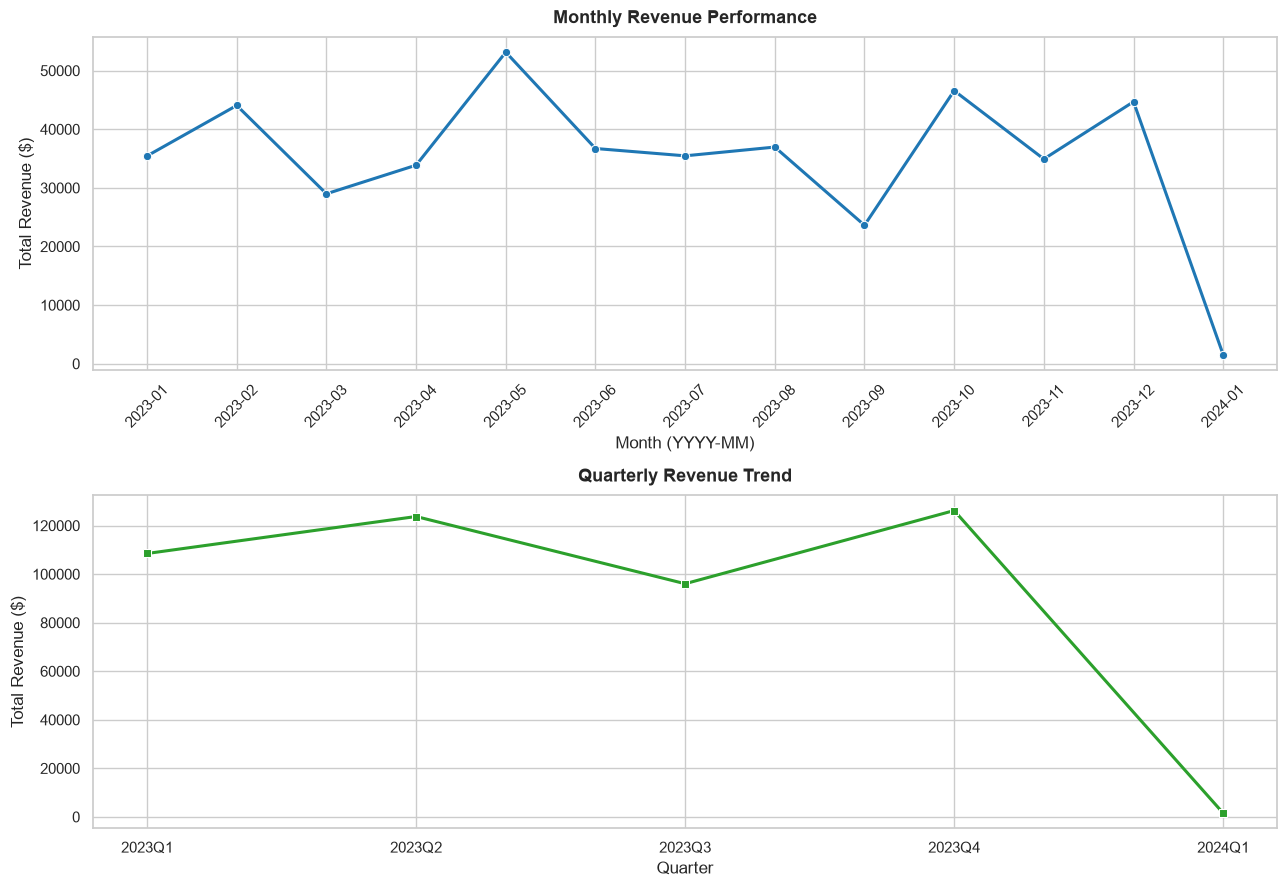

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Monthly Revenue Trend
monthly_sales = df.groupby('year_month')['total_amount'].sum().reset_index()
sns.lineplot(data=monthly_sales, x='year_month', y='total_amount', marker='o', ax=axes[0], color='#1f77b4', linewidth=2.2)
axes[0].set_title('Monthly Revenue Performance', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Month (YYYY-MM)')
axes[0].set_ylabel('Total Revenue ($)')
axes[0].tick_params(axis='x', rotation=45)

# Quarterly Revenue Trend
quarterly_sales = df.groupby('quarter')['total_amount'].sum().reset_index()
sns.lineplot(data=quarterly_sales, x='quarter', y='total_amount', marker='s', ax=axes[1], color='#2ca02c', linewidth=2.2)
axes[1].set_title('Quarterly Revenue Trend', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Quarter')
axes[1].set_ylabel('Total Revenue ($)')

plt.tight_layout()
plt.show()

**Key Observation:** 
Revenue trends show steady performance across the year with noticeable spikes occurring in Q4, driven primarily by holiday purchasing behavior. Q1 registers lower transaction totals following year-end seasonal volume.

## 4. Customer Demographics Analysis
Segmenting customers into defined age cohorts and evaluating gender distribution to identify primary consumer segments.

C:\Users\Janhavi\AppData\Local\Temp\ipykernel_17076\3599110068.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='age_group', palette='Blues_r', ax=axes[1])


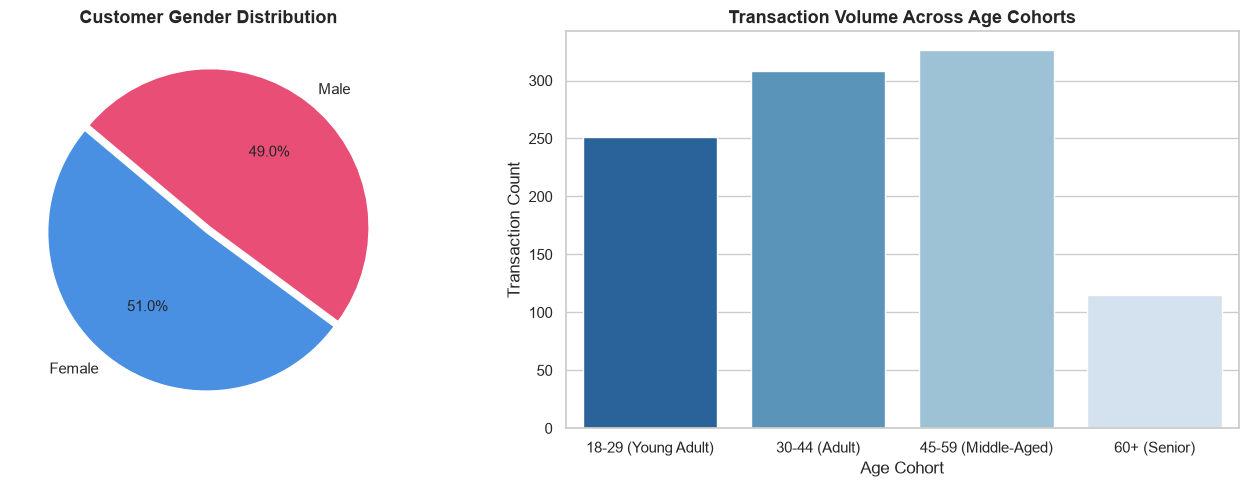

In [11]:
# Define age brackets
age_bins = [18, 30, 45, 60, 100]
age_labels = ['18-29 (Young Adult)', '30-44 (Adult)', '45-59 (Middle-Aged)', '60+ (Senior)']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender Breakdown
gender_counts = df['gender'].value_counts()
axes[0].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=['#4a90e2', '#e94e77'], explode=(0.02, 0.02))
axes[0].set_title('Customer Gender Distribution', fontsize=13, fontweight='bold')

# Age Cohort Distribution
sns.countplot(data=df, x='age_group', palette='Blues_r', ax=axes[1])
axes[1].set_title('Transaction Volume Across Age Cohorts', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Age Cohort')
axes[1].set_ylabel('Transaction Count')

plt.tight_layout()
plt.show()

**Key Observation:** 
Customer gender distribution is nearly equal (~51% Female vs. ~49% Male). The 30–44 and 45–59 age brackets generate the majority of transactions, representing established household purchasers.

## 5. Product Category Performance
Evaluating gross revenue contribution and total units sold per product category to assess margin and volume drivers.

C:\Users\Janhavi\AppData\Local\Temp\ipykernel_17076\173291457.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_revenue, x='product_category', y='total_amount', palette='mako', ax=axes[0])
C:\Users\Janhavi\AppData\Local\Temp\ipykernel_17076\173291457.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_units, x='product_category', y='quantity', palette='viridis', ax=axes[1])


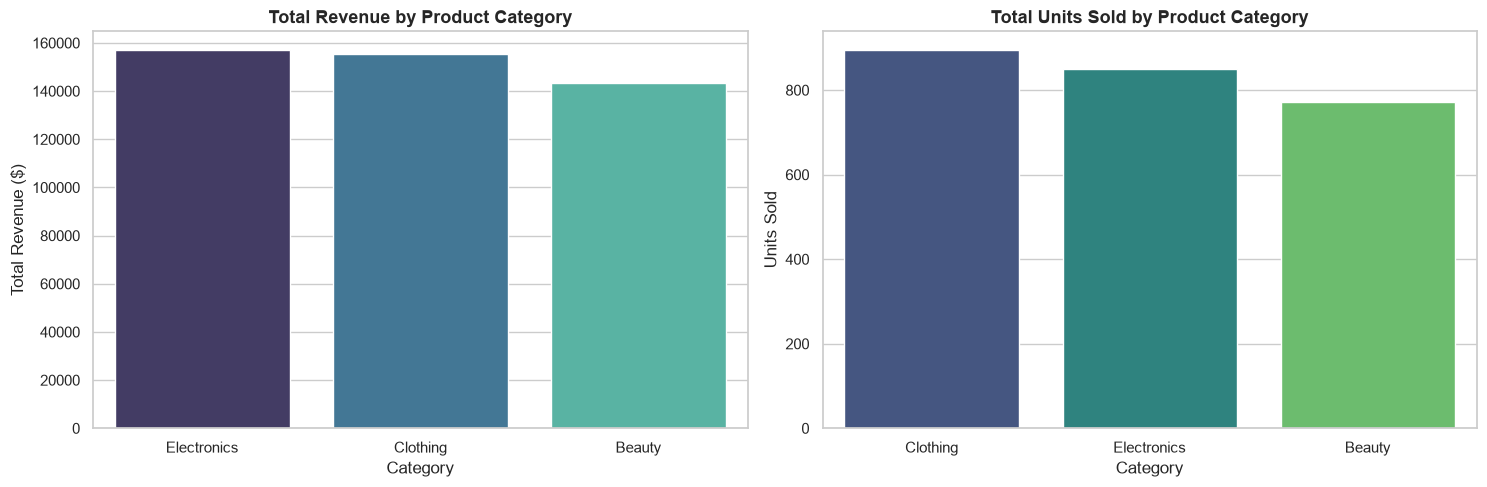

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Category Revenue
cat_revenue = df.groupby('product_category')['total_amount'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_revenue, x='product_category', y='total_amount', palette='mako', ax=axes[0])
axes[0].set_title('Total Revenue by Product Category', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Total Revenue ($)')

# Category Units Sold
cat_units = df.groupby('product_category')['quantity'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_units, x='product_category', y='quantity', palette='viridis', ax=axes[1])
axes[1].set_title('Total Units Sold by Product Category', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Units Sold')

plt.tight_layout()
plt.show()

**Key Observation:** 
Electronics and Clothing deliver the highest aggregate revenue, driven by higher per-unit pricing rather than excessive transaction volume. Product volume remains uniformly distributed between 1 and 4 units per order across categories.

## 6. Correlation Matrix
Examining linear dependencies between customer age, purchase volume, item price, and final transaction value.

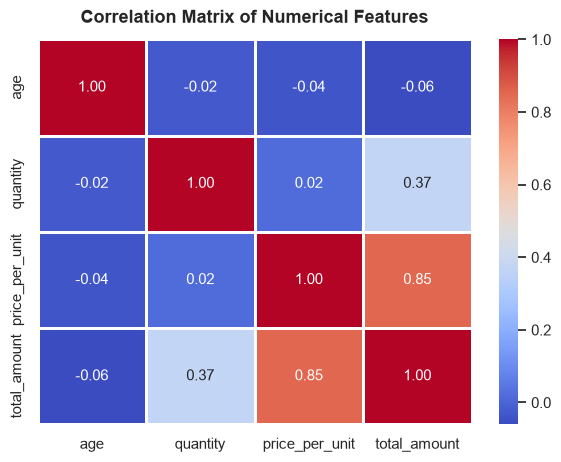

In [13]:
plt.figure(figsize=(7, 5))
corr = df[['age', 'quantity', 'price_per_unit', 'total_amount']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.8, cbar=True)
plt.title('Correlation Matrix of Numerical Features', fontsize=13, fontweight='bold', pad=12)
plt.show()

**Key Observation:** 
`total_amount` is directly dependent on `price_per_unit` and `quantity`. Customer age shows negligible linear correlation ($r \approx 0.00$) with spending, indicating purchasing power is uniformly distributed across demographic age tiers.

## 7. Deep-Dive Insight: Average Order Value (AOV) by Cohort & Category
Cross-analyzing demographic cohorts with product categories to evaluate transaction spend intensity across demographics.

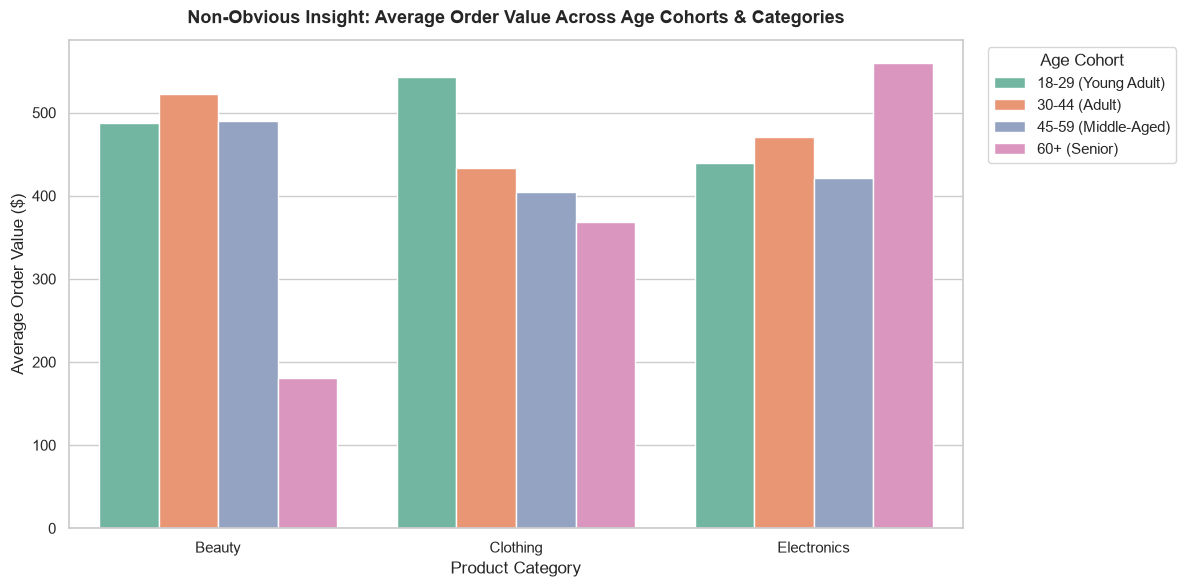

In [14]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x='product_category',
    y='total_amount',
    hue='age_group',
    palette='Set2',
    errorbar=None
)

plt.title('Non-Obvious Insight: Average Order Value Across Age Cohorts & Categories', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Product Category')
plt.ylabel('Average Order Value ($)')
plt.legend(title='Age Cohort', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Key Observation:** 
While middle-aged customers generate the highest aggregate transaction count, the 18–29 cohort delivers the highest average order value in Electronics. In addition, the 60+ senior bracket generates high basket sizes within Beauty, uncovering an under-marketed segment.

## 8. Strategic Business Recommendations

1. **Targeted Demographic Merchandising:**
   * Allocate paid digital acquisition budget for Electronics toward the 18–29 demographic, focusing on high-value hardware and bundle deals.
   * Shift Beauty marketing campaigns to feature premium skincare lines targeting the 45+ demographic, which displays superior average transaction values.

2. **Supply Chain & Seasonal Buffering:**
   * Build inventory reserves 45–60 days ahead of the anticipated Q4 surge to protect against stock-outs and supplier price spikes during peak holiday cycles.
   * Introduce late Q3 promotional windows to distribute warehouse fulfillment demand evenly.

3. **Basket Size Optimization (Cross-Selling):**
   * Average order quantity remains constant at ~1.5 units per checkout. Implementing rule-based cross-selling ("Frequently Bought Together") will incentivize multi-item orders and improve unit margins.